# AYA pancreatic neoplasms (ages 15-39), SEER: stage vs machine learning — REVISED for clinical use

**Environment:** Python 3.13. Data source: SEER*Stat database *Incidence - SEER Research Data, 2000-2022* (add registries and submission/release date from the database name in SEER*Stat).

**Revision notes:** clean AYA export (1,674 rows), YEAR_MAX 2021, 2018+ grade fix, tumor location, SPN histology group, recalibration, decision curves, risk tiers, histology strata, second temporal split, RMST, time-varying stage effect, missingness + sensitivity analyses (Section 7b onward).

**What this notebook does (run top to bottom):**
1. Loads your SEER\*Stat CSV export and auto-detects the columns
2. Builds the analytic cohort (with a CONSORT-style flow table)
3. Table 1, Kaplan–Meier survival, multivariable Cox model
4. 12-month mortality prediction with a **temporal validation split** (train on earlier years, test on later years), bootstrap CIs, calibration, and the 95%-sensitivity operating point
5. Saves every table/figure and auto-writes the key numbers for your Results section

**Important:** SEER contains only people who already have cancer, so this is a **prognosis** analysis, not symptom triage. Do not upload the raw SEER file to GitHub (SEER data-use agreement).

**Before you start:** in SEER\*Stat export with *CSV Defaults*, tick *Output variable names before data*, and use *Labels enclosed in Quotes*.

In [1]:
!pip -q install lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, re, io, json, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ------------------ SETTINGS (edit here) ------------------
OUT          = "oncosense_outputs"   # all results are saved here
SEED         = 42
YEAR_MIN     = 2004                  # diagnosis years to include
YEAR_MAX     = 2021
TEST_FROM    = 2018                  # temporal validation: train < 2018, test >= 2018
HORIZON      = 12                    # months, for the mortality-prediction task
ML_YEAR_MAX  = 2021                  # last dx year for ML: later cases lack 12 months of follow-up (SEER follow-up ends ~Dec 2022)
TARGET_SENS  = 0.95                  # sensitivity for the operating-point analysis
SPLIT2       = 2016                 # second temporal split for robustness
N_BOOT       = 500                   # bootstrap resamples for AUROC CI
SEER_DB      = "SEER*Stat Database: Incidence - SEER Research Data, 2000-2022"   # add registries + release date, e.g. "..., 17 registries, Nov 2024 submission"
REQUIRED_PY  = (3, 13)               # analyses reported for Python 3.13
# -----------------------------------------------------------
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Ready.")

Ready.


In [3]:
# ---- Software environment (paste into Methods; saved to software_versions.txt) ----
import sys, platform
from importlib.metadata import version, PackageNotFoundError
if sys.version_info[:2] != REQUIRED_PY:
    print(f"!! Running Python {platform.python_version()}, manuscript states Python {REQUIRED_PY[0]}.{REQUIRED_PY[1]}. Update the Methods text or rerun on {REQUIRED_PY[0]}.{REQUIRED_PY[1]}.")
PKGS = ["lifelines", "scikit-learn", "pandas", "numpy", "scipy", "statsmodels", "matplotlib"]
VERS = {}
for p in PKGS:
    try: VERS[p] = version(p)
    except PackageNotFoundError: VERS[p] = "not installed"
SOFT_TXT = (f"Analyses were performed in Python {platform.python_version()} (" +
            ", ".join(f"{k} {v}" for k, v in VERS.items()) + ").")
print(SOFT_TXT)
print("Data source:", SEER_DB)
with open(f"{OUT}/software_versions.txt", "w") as f:
    f.write(SOFT_TXT + "\nData source: " + SEER_DB + "\n")


Analyses were performed in Python 3.13.18 (lifelines 0.30.3, scikit-learn 1.6.1, pandas 2.2.3, numpy 2.4.6, scipy 1.16.3, statsmodels 0.15.0, matplotlib 3.10.0).
Data source: SEER*Stat Database: Incidence - SEER Research Data, 2000-2022


## 1. Load data

In [4]:
# Option A (default): upload the CSV from your computer.
# Option B: for very large files, mount Google Drive and set DATA_PATH manually, e.g.
#   from google.colab import drive; drive.mount('/content/drive')
#   DATA_PATH = '/content/drive/MyDrive/SEER_pancreas.csv'

DATA_PATH = os.environ.get("SEER_CSV")          # used only for offline testing
if DATA_PATH is None:
    try:
        from google.colab import files
        up = files.upload()
        DATA_PATH = list(up.keys())[0]
    except ImportError:
        DATA_PATH = "SEER_pancreas.csv"

def load_seer(path):
    with open(path, "rb") as f: head = f.read(4096)
    print(f"File size: {os.path.getsize(path)/1e6:.1f} MB | first bytes: {head[:60]!r}")
    comp = None
    if head[:2] == b"\x1f\x8b": comp = "gzip"
    elif head[:2] == b"PK":
        raise ValueError("This is an Excel/ZIP file, not a CSV. Re-export from SEER*Stat as CSV (or unzip it first).")
    encs = (["utf-16"] if head[:2] in (b"\xff\xfe", b"\xfe\xff") else []) + ["utf-8-sig", "cp1252", "latin-1"]
    first_line = head.decode("latin-1", errors="ignore").split("\n")[0]
    sep = "\t" if first_line.count("\t") > first_line.count(",") else ","
    last_err = None
    for enc in encs:
        try:
            df = pd.read_csv(path, sep=sep, dtype=str, low_memory=False, encoding=enc, compression=comp)
            sep_name = "TAB" if sep == "\t" else "COMMA"
            print(f"Loaded OK with encoding={enc!r}, delimiter={sep_name}")
            return df
        except UnicodeError as e:
            last_err = e
            print(f"  encoding {enc!r} failed, trying next...")
    raise last_err

raw = load_seer(DATA_PATH)
raw.columns = [c.strip().strip('"') for c in raw.columns]
print("Shape:", raw.shape, "(clean AYA export should have 1,674 rows)")
if not any(re.search(r"age recode|year of diagnosis|survival months", c, re.I) for c in raw.columns):
    print("!! Header row not recognised. Column names found:", list(raw.columns)[:8],
          "\n   Re-export with 'Output variable names before data' ticked.")
raw.head(3)

Saving seer data.csv to seer data.csv
File size: 0.6 MB | first bytes: b'"Age recode with <1 year olds and 90+","Sex","Year of diagno'
Loaded OK with encoding='utf-8-sig', delimiter=COMMA
Shape: (1674, 25) (clean AYA export should have 1,674 rows)


,Age recode with <1 year olds and 90+,Sex,Year of diagnosis,"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",Primary Site - labeled,Histologic Type ICD-O-3,Behavior recode for analysis,Combined Summary Stage with Expanded Regional Codes (2004+),Summary stage 2000 (1998-2017),Tumor Size Summary (2016+),...,Marital status at diagnosis,Survival months,Survival months flag,COD to site recode,SEER cause-specific death classification,Vital status recode (study cutoff used),Mets at DX-Other (2016+),Sequence number,Grade Recode (thru 2017),Derived Summary Grade 2018 (2018+)
0,15-19 years,Male,2000,Non-Hispanic White,"C25.9-Pancreas, NOS",8246,Malignant,Blank(s),Unknown/unstaged,Blank(s),...,Single (never married),0259,Complete dates are available and there are mor...,Stomach and Duodenal Ulcers,Dead (attributable to this cancer dx),Dead,Blank(s),2nd of 2 or more primaries,Unknown,Blank(s)
1,15-19 years,Male,2000,Non-Hispanic Black,C25.8-Overlapping lesion of pancreas,8890,Malignant,Blank(s),Distant,Blank(s),...,Single (never married),0136,Incomplete dates are available and there canno...,Soft Tissue including Heart,Dead (attributable to this cancer dx),Dead,Blank(s),One primary only,Undifferentiated; anaplastic; Grade IV,Blank(s)
2,15-19 years,Male,2000,Hispanic (All Races),C25.0-Head of pancreas,8010,Malignant,Blank(s),Distant,Blank(s),...,Single (never married),0098,Complete dates are available and there are mor...,Alive,Alive or dead of other cause,Alive,Blank(s),One primary only,Poorly differentiated; Grade III,Blank(s)


## 2. Detect columns (check this printout!)

In [5]:
PATTERNS = {
 "age":      [r"^age recode"],
 "sex":      [r"^sex$"],
 "race":     [r"^race and origin recode", r"^race recode", r"^race"],
 "year":     [r"^year of diagnosis$"],
 "months":   [r"^survival months$"],
 "flag":     [r"^survival months flag"],
 "vital":    [r"^vital status recode", r"^vital status"],
 "csd":      [r"^seer cause-specific death"],
 "seq":      [r"^sequence number"],
 "site":     [r"^primary site - labeled", r"^site recode icd-o-3/who 2008$", r"^primary site$", r"^site recode"],
 "hist":     [r"^histologic type icd-o-3", r"^histology recode", r"^histologic"],
 "behavior": [r"^behavior recode", r"^behavior code"],
 "grade":    [r"^grade recode", r"^derived summary grade", r"^grade pathological", r"^grade clinical"],
 "stage":    [r"combined summary stage", r"summary stage 2000", r"^seer historic stage", r"summary stage"],
 "size":     [r"^tumor size summary", r"^cs tumor size", r"tumor size"],
 "surgery":  [r"^rx summ.*surg prim site", r"surg prim site"],
 "radiation":[r"^radiation recode", r"^radiation"],
 "chemo":    [r"^chemotherapy recode", r"^chemotherapy"],
 "marital":  [r"^marital status"],
}

# ---- MANUAL OVERRIDES (optional) ----
# e.g. OVERRIDE = {"surgery": ["RX Summ--Surg Prim Site (1998-2022)"]}
OVERRIDE = {}

def find_cols(pats):
    hits = []
    for p in pats:
        for c in raw.columns:
            if re.search(p, c, flags=re.I) and c not in hits:
                hits.append(c)
    return hits

colmap = {k: find_cols(v) for k, v in PATTERNS.items()}
for k, v in OVERRIDE.items():
    colmap[k] = [c for c in v if c in raw.columns]
    bad = [c for c in v if c not in raw.columns]
    if bad: print(f"!! OVERRIDE for '{k}' not found in file: {bad}")

MULTI = {"stage", "grade", "size"}          # these are coalesced across several columns
for k in colmap:
    if k not in MULTI and len(colmap[k]) > 1:
        colmap[k] = colmap[k][:1]

BLANKS = {"blank(s)", "unknown", "unstaged", "unknown/unstaged", "na", "nan", "", "not applicable"}
def coverage(c):
    s = raw[c].astype("string").str.strip().str.lower()
    return 1 - (s.isna() | s.isin(BLANKS)).mean()

print(f"{'variable':10s} {'coverage':>8s}   column")
for k, v in colmap.items():
    if not v: print(f"{k:10s} {'':>8s}   -- NOT FOUND --")
    for c in v: print(f"{k:10s} {coverage(c):8.0%}   {c}")

REQUIRED = ["age", "sex", "year", "months", "vital"]
missing_req = [k for k in REQUIRED if not colmap[k]]
assert not missing_req, f"Required columns missing from export: {missing_req}. Add them in SEER*Stat or set OVERRIDE."
RECOMMENDED = ["site", "hist", "stage", "seq", "flag", "surgery", "chemo", "radiation", "marital", "size"]
warn = [k for k in RECOMMENDED if not colmap[k]]
if warn: print("\n!! Recommended variables missing (analysis will run without them, with limits):", warn)

variable   coverage   column
age            100%   Age recode with <1 year olds and 90+
sex            100%   Sex
race           100%   Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)
year           100%   Year of diagnosis
months          99%   Survival months
flag           100%   Survival months flag
vital          100%   Vital status recode (study cutoff used)
csd            100%   SEER cause-specific death classification
seq            100%   Sequence number
site           100%   Primary Site - labeled
hist           100%   Histologic Type ICD-O-3
behavior       100%   Behavior recode for analysis
grade           35%   Grade Recode (thru 2017)
grade           29%   Derived Summary Grade 2018 (2018+)
stage           89%   Combined Summary Stage with Expanded Regional Codes (2004+)
stage           66%   Summary stage 2000 (1998-2017)
size            42%   Tumor Size Summary (2016+)
size            47%   CS tumor size (2004-2015)
surgery        100%   RX Summ--Surg Prim Si

## 3. Clean variables

In [6]:
MISSING = {"blank(s)", "unknown", "unstaged", "unknown/unstaged", "na", "nan", "", "not applicable", "unk", "not available"}
def clean(s):
    s = s.astype("string").str.strip()
    return s.mask(s.str.lower().isin(MISSING))

def coalesce(cols, fn=lambda s: s):
    out = None
    for c in cols:
        v = fn(clean(raw[c]))
        out = v if out is None else out.combine_first(v)
    return out

def parse_age(x):
    if pd.isna(x): return np.nan
    x = str(x)
    m = re.match(r"(\d+)\s*-\s*(\d+)", x)
    if m: return (int(m.group(1)) + int(m.group(2))) / 2
    m = re.match(r"(\d+)\s*\+", x)
    if m: return int(m.group(1)) + 2
    m = re.match(r"^(\d+)", x)
    if m: return float(m.group(1))
    if x.startswith("<1"): return 0.5
    return np.nan

def map_stage(x):
    if pd.isna(x): return np.nan
    t = x.lower()
    if "local" in t: return "Localized"
    if "regional" in t: return "Regional"
    if "distant" in t: return "Distant"
    return np.nan

def map_grade(x):
    if pd.isna(x): return np.nan
    t = x.lower().strip()
    if t in {"3","4","c","d"} or re.search(r"grade iv\b|undiff|anaplast|grade iii\b|poor", t): return "G3-4"
    if t in {"2","b"} or re.search(r"grade ii\b|moderate", t): return "G2"
    if t in {"1","a"} or re.search(r"grade i\b|well", t): return "G1"
    return np.nan

def hist_group(x):
    if pd.isna(x): return "Unknown"
    m = re.search(r"(\d{4})", x)
    if not m: return "Unknown"
    h = int(m.group(1))
    if h == 8452: return "Solid pseudopapillary"
    if h in (8140, 8141, 8500, 8480, 8481, 8255, 8260, 8211): return "Adenocarcinoma"
    if 8150 <= h <= 8158 or 8240 <= h <= 8249: return "Neuroendocrine"
    return "Other"

def map_loc(x):
    if pd.isna(x): return "Unknown"
    m = re.search(r"C25\.(\d)", x)
    if not m: return "Unknown"
    return {"0": "Head", "1": "Body/Tail", "2": "Body/Tail"}.get(m.group(1), "Other/NOS")

def map_surg(x):
    if pd.isna(x): return np.nan
    t = x.lower().strip()
    if t.startswith("none") or "not recommended" in t or t in {"0", "00"}: return "No"
    if "unknown" in t or "recommended" in t or "refused" in t or t in {"99", "126"}: return np.nan
    return "Yes"

def map_rad(x):
    if pd.isna(x): return np.nan
    t = x.lower()
    if t.startswith("none") or "refused" in t: return "No/Unk"
    if "unknown if" in t or "recommended" in t: return np.nan
    return "Yes"

def map_chemo(x):
    if pd.isna(x): return np.nan
    return "Yes" if x.lower().startswith("yes") else "No/Unk"

def parse_size(s):
    v = pd.to_numeric(s, errors="coerce")
    return v.where((v >= 1) & (v <= 988))

d = pd.DataFrame(index=raw.index)
d["age"]    = clean(raw[colmap["age"][0]]).map(parse_age).astype(float)
d["sex"]    = clean(raw[colmap["sex"][0]])
d["race"]   = clean(raw[colmap["race"][0]]) if colmap["race"] else pd.NA
d["year"]   = pd.to_numeric(raw[colmap["year"][0]], errors="coerce")
d["time"]   = pd.to_numeric(raw[colmap["months"][0]], errors="coerce")
d["event"]  = (clean(raw[colmap["vital"][0]]).str.lower() == "dead").astype(int)
d["cs_event"] = (clean(raw[colmap["csd"][0]]).str.contains("attributable", case=False, na=False)).astype(int) if colmap["csd"] else np.nan
d["stage"]  = coalesce(colmap["stage"], lambda s: s.map(map_stage)) if colmap["stage"] else pd.NA
d["grade"]  = coalesce(colmap["grade"], lambda s: s.map(map_grade)) if colmap["grade"] else pd.NA
d["hist_group"] = clean(raw[colmap["hist"][0]]).map(hist_group) if colmap["hist"] else "Unknown"
d["tumor_size"] = None
if colmap["size"]:
    sz = None
    for c in colmap["size"]:
        v = parse_size(raw[c]); sz = v if sz is None else sz.combine_first(v)
    d["tumor_size"] = sz
d["marital"]   = clean(raw[colmap["marital"][0]]) if colmap["marital"] else pd.NA
d["surgery"]   = clean(raw[colmap["surgery"][0]]).map(map_surg) if colmap["surgery"] else pd.NA
d["radiation"] = clean(raw[colmap["radiation"][0]]).map(map_rad) if colmap["radiation"] else pd.NA
d["chemo"]     = clean(raw[colmap["chemo"][0]]).map(map_chemo) if colmap["chemo"] else pd.NA
d["tumor_size"] = pd.to_numeric(d["tumor_size"], errors="coerce")
d["location"] = raw[colmap["site"][0]].astype("string").map(map_loc) if colmap["site"] else "Unknown"

# --- cohort filters (flow table) ---
flow = [("Records in SEER export", len(raw))]
keep = pd.Series(True, index=d.index)
def step(label, mask):
    global keep
    keep = keep & mask.fillna(False)
    flow.append((label, int(keep.sum())))

if colmap["site"]:
    s = raw[colmap["site"][0]].astype("string")
    step("Pancreas primary (C25.x)", s.str.contains(r"C25|pancrea", case=False, na=False) | s.str.match(r"^\s*25\d\s*$", na=False))
if colmap["behavior"]:
    step("Malignant behavior", raw[colmap["behavior"][0]].astype("string").str.contains("malignant", case=False, na=False))
step("Age 15-39 years (AYA)", d["age"].between(15, 39))
step(f"Diagnosed {YEAR_MIN}-{YEAR_MAX}", d["year"].between(YEAR_MIN, YEAR_MAX))
if colmap["seq"]:
    s = raw[colmap["seq"][0]].astype("string")
    step("First/only primary (one record per patient)", s.str.contains(r"One primary only|1st of", case=False, na=False))
step("Valid survival time", d["time"].notna())
if colmap["flag"]:
    step("Excl. death-certificate/autopsy-only", ~raw[colmap["flag"][0]].astype("string").str.contains("Not calculated", case=False, na=False))
step("Known age and sex", d["age"].notna() & d["sex"].notna())

d = d[keep].copy()
for c in ["race", "marital", "stage", "grade", "surgery", "radiation", "chemo", "location"]:
    d[c] = d[c].astype("object").where(d[c].notna(), "Unknown")
d["stage"] = pd.Categorical(d["stage"], ["Localized", "Regional", "Distant", "Unknown"])

flow_df = pd.DataFrame(flow, columns=["Step", "N remaining"])
flow_df.to_csv(f"{OUT}/cohort_flow.csv", index=False)
display(flow_df)
print(f"Final analytic cohort: n = {len(d):,}")
print("Data source:", SEER_DB)

,Step,N remaining
0,Records in SEER export,1674
1,Pancreas primary (C25.x),1674
2,Malignant behavior,1674
3,Age 15-39 years (AYA),1674
4,Diagnosed 2004-2021,1487
5,First/only primary (one record per patient),1416
6,Valid survival time,1406
7,Excl. death-certificate/autopsy-only,1406
8,Known age and sex,1406


Final analytic cohort: n = 1,406
Data source: SEER*Stat Database: Incidence - SEER Research Data, 2000-2022


### Sanity check: category counts (verify mappings look right)

In [7]:
for c in ["sex", "race", "stage", "grade", "hist_group", "location", "surgery", "radiation", "chemo", "marital"]:
    print(f"--- {c} ---"); print(d[c].value_counts(dropna=False).head(8).to_string(), "\n")
print("Follow-up (months): median", d.time.median(), "| deaths:", int(d.event.sum()), f"({d.event.mean():.1%})")
print("Missing tumor size:", f"{d.tumor_size.isna().mean():.1%}")

--- sex ---
sex
Female    842
Male      564 

--- race ---
race
Non-Hispanic White                            658
Hispanic (All Races)                          387
Non-Hispanic Black                            192
Non-Hispanic Asian or Pacific Islander        147
Non-Hispanic American Indian/Alaska Native     15
Non-Hispanic Unknown Race                       7 

--- stage ---
stage
Localized    577
Distant      491
Regional     274
Unknown       64 

--- grade ---
grade
Unknown    744
G1         365
G2         192
G3-4       105 

--- hist_group ---
hist_group
Neuroendocrine           583
Adenocarcinoma           363
Solid pseudopapillary    292
Other                    168 

--- location ---
location
Body/Tail    553
Head         487
Other/NOS    366 

--- surgery ---
surgery
Yes        796
No         599
Unknown     11 

--- radiation ---
radiation
No/Unk     1291
Yes         109
Unknown       6 

--- chemo ---
chemo
No/Unk    930
Yes       476 

--- marital ---
marital
Single (neve

In [8]:
# ---- Age check: confirm every analysed patient is 15-39 (reviewer request) ----
agecol = colmap["age"][0]
ag = raw.loc[d.index, agecol].astype(str).str.strip().value_counts().rename("n").to_frame()
ag["%"] = (ag.n / ag.n.sum() * 100).round(1)
ag = ag.sort_index()
ag.to_csv(f"{OUT}/age_groups.csv"); display(ag)
print(f"Age groups present: {list(ag.index)}")
print(f"Minimum / maximum age-group midpoints used: {d.age.min():.0f} / {d.age.max():.0f}; outside 15-39 (by group): {int((~d.age.between(15, 39)).sum())}")
print("Export was restricted to ages 15-39 in SEER*Stat; all records at the age-filter step are retained (see cohort flow).")


,n,%
Age recode with <1 year olds and 90+,,
15-19 years,122,8.7
20-24 years,188,13.4
25-29 years,290,20.6
30-34 years,621,44.2
35-39 years,185,13.2


Age groups present: ['15-19 years', '20-24 years', '25-29 years', '30-34 years', '35-39 years']
Minimum / maximum age-group midpoints used: 17 / 37; outside 15-39 (by group): 0
Export was restricted to ages 15-39 in SEER*Stat; all records at the age-filter step are retained (see cohort flow).


## 4. Table 1

In [9]:
def fmt_cont(s): return f"{s.median():.1f} ({s.quantile(.25):.1f}-{s.quantile(.75):.1f})"
def table1(d, by="stage"):
    groups = [("Overall", d)] + [(str(k), g) for k, g in d.groupby(by, observed=True)]
    rows = []
    def add_cont(label, col):
        rows.append([label + ", median (IQR)"] + [fmt_cont(g[col].dropna()) if g[col].notna().any() else "-" for _, g in groups])
    def add_cat(label, col):
        rows.append([f"**{label}**"] + [""] * len(groups))
        for lv in d[col].astype(str).value_counts().index:
            rows.append([f"   {lv}"] + [f"{(g[col].astype(str) == lv).sum():,} ({(g[col].astype(str) == lv).mean():.1%})" for _, g in groups])
    rows.append(["N"] + [f"{len(g):,}" for _, g in groups])
    add_cont("Age, years", "age")
    add_cat("Sex", "sex"); add_cat("Race", "race"); add_cat("Histology", "hist_group"); add_cat("Tumor location", "location"); add_cat("Grade", "grade")
    if d.tumor_size.notna().any(): add_cont("Tumor size, mm", "tumor_size")
    for lab, col in [("Surgery", "surgery"), ("Chemotherapy", "chemo"), ("Radiation", "radiation")]:
        if (d[col] != "Unknown").any(): add_cat(lab, col)
    rows.append(["Follow-up, months, median (IQR)"] + [fmt_cont(g["time"]) for _, g in groups])
    rows.append(["Deaths, n (%)"] + [f"{int(g.event.sum()):,} ({g.event.mean():.1%})" for _, g in groups])
    return pd.DataFrame(rows, columns=["Characteristic"] + [n for n, _ in groups])
t1 = table1(d)
t1.to_csv(f"{OUT}/table1.csv", index=False)
display(t1)

,Characteristic,Overall,Localized,Regional,Distant,Unknown
0,N,"1,406",577,274,491,64
1,"Age, years, median (IQR)",32.0 (27.0-32.0),27.0 (22.0-32.0),32.0 (27.0-32.0),32.0 (27.0-32.0),32.0 (25.8-32.0)
2,**Sex**,,,,,
3,Female,842 (59.9%),413 (71.6%),141 (51.5%),248 (50.5%),40 (62.5%)
4,Male,564 (40.1%),164 (28.4%),133 (48.5%),243 (49.5%),24 (37.5%)
5,**Race**,,,,,
6,Non-Hispanic White,658 (46.8%),275 (47.7%),114 (41.6%),239 (48.7%),30 (46.9%)
7,Hispanic (All Races),387 (27.5%),174 (30.2%),80 (29.2%),115 (23.4%),18 (28.1%)
8,Non-Hispanic Black,192 (13.7%),63 (10.9%),43 (15.7%),76 (15.5%),10 (15.6%)
9,Non-Hispanic Asian or Pacific Islander,147 (10.5%),57 (9.9%),33 (12.0%),53 (10.8%),4 (6.2%)


## 5. Kaplan–Meier survival

,Group,N,Deaths,Median OS (mo),Median 95% CI,12-mo OS,24-mo OS,60-mo OS
0,All patients,1406,562,155.0,121.0-inf,78.5% (76.2%-80.6%),70.0% (67.4%-72.3%),60.5% (57.7%-63.2%)
1,Localized,577,44,inf,inf-inf,97.5% (95.8%-98.5%),96.7% (94.9%-97.9%),94.1% (91.5%-95.9%)
2,Regional,274,104,162.0,107.0-inf,87.3% (82.7%-90.8%),75.2% (69.4%-80.0%),65.8% (59.5%-71.4%)
3,Distant,491,388,13.0,10.0-16.0,50.8% (46.2%-55.1%),35.5% (31.2%-39.8%),19.4% (15.7%-23.3%)


Log-rank test across stages: chi2 = 711.1, p = 3.92e-155


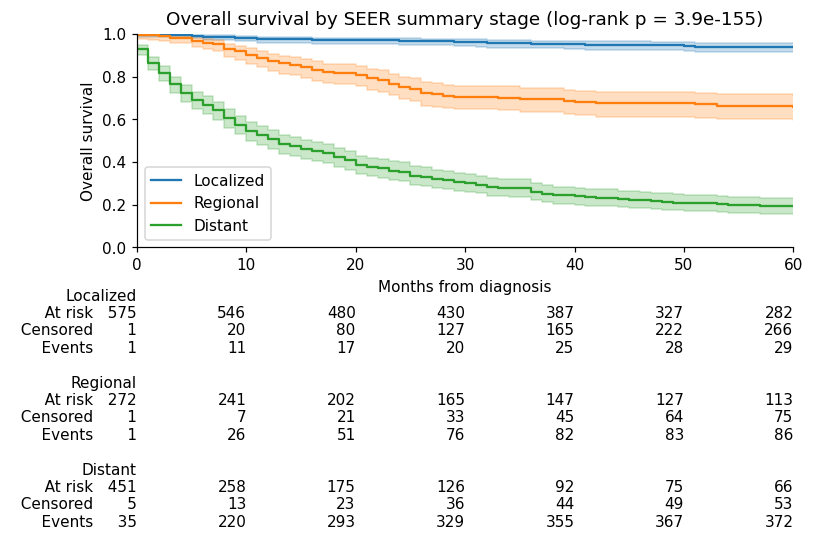

In [10]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import median_survival_times
from lifelines.plotting import add_at_risk_counts

def surv_at(kmf, t):
    sf = kmf.survival_function_at_times([t]).values[0]
    ci = kmf.confidence_interval_survival_function_
    row = ci.loc[:t].iloc[-1]
    return sf, row.iloc[0], row.iloc[1]

def km_summary(g, label):
    k = KaplanMeierFitter().fit(g.time, g.event, label=label)
    med = k.median_survival_time_
    mci = median_survival_times(k.confidence_interval_).iloc[0]
    out = {"Group": label, "N": len(g), "Deaths": int(g.event.sum()), "Median OS (mo)": med,
           "Median 95% CI": f"{mci.iloc[0]:.1f}-{mci.iloc[1]:.1f}"}
    for t in (12, 24, 60):
        sf, lo, hi = surv_at(k, t)
        out[f"{t}-mo OS"] = f"{sf:.1%} ({lo:.1%}-{hi:.1%})"
    return out, k

rows, kms = [], []
r, k_all = km_summary(d, "All patients"); rows.append(r)
staged = d[d.stage.isin(["Localized", "Regional", "Distant"])]
for st in ["Localized", "Regional", "Distant"]:
    g = staged[staged.stage == st]
    if len(g) > 20:
        r, k = km_summary(g, st); rows.append(r); kms.append(k)
km_tab = pd.DataFrame(rows); km_tab.to_csv(f"{OUT}/km_summary.csv", index=False); display(km_tab)

lr = multivariate_logrank_test(staged.time, staged.stage.astype(str), staged.event)
print(f"Log-rank test across stages: chi2 = {lr.test_statistic:.1f}, p = {lr.p_value:.2e}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for k in kms: k.plot_survival_function(ax=ax, ci_show=True)
ax.set_xlim(0, 60); ax.set_ylim(0, 1); ax.set_xlabel("Months from diagnosis"); ax.set_ylabel("Overall survival")
ax.set_title(f"Overall survival by SEER summary stage (log-rank p = {lr.p_value:.1e})")
try: add_at_risk_counts(*kms, ax=ax)
except Exception as e: print("risk table skipped:", e)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_km_by_stage.png", dpi=300); plt.show()

## 6. Multivariable Cox regression

,HR,CI_low,CI_high,p
covariate,,,,
age_per10yr,1.262,1.051,1.515,0.013
male,1.163,0.981,1.378,0.083
dx_year_per5,0.964,0.884,1.051,0.407
stage_Regional,2.547,1.758,3.691,0.000
stage_Distant,7.654,5.464,10.723,0.000
stage_Unknown,1.922,1.141,3.236,0.014
grade_G2,1.394,0.942,2.064,0.097
grade_G3-4,2.977,2.016,4.396,0.000
grade_Unknown,2.559,1.821,3.595,0.000


Concordance (C-index): 0.867


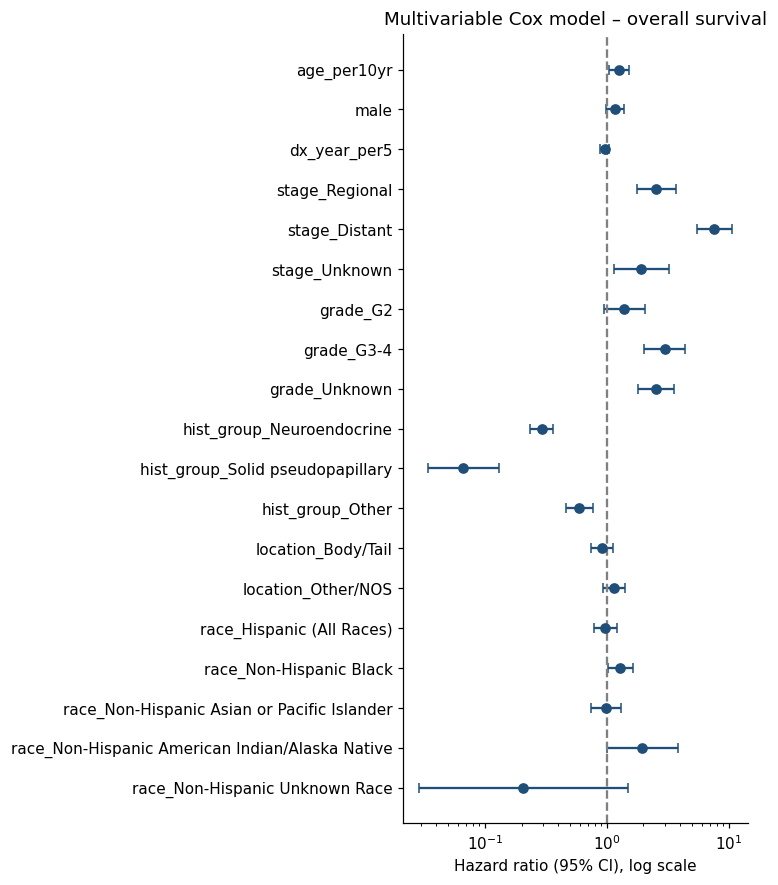

Proportional-hazards test (Schoenfeld):


,test_statistic,p,-log2(p)
age_per10yr,0.9777,0.3228,1.6315
dx_year_per5,1.2737,0.2591,1.9485
grade_G2,0.6650,0.4148,1.2696
grade_G3-4,1.9346,0.1643,2.6060
grade_Unknown,0.4850,0.4862,1.0405
hist_group_Neuroendocrine,5.0578,0.0245,5.3501
hist_group_Other,8.2752,0.0040,7.9589
hist_group_Solid pseudopapillary,2.9412,0.0863,3.5337
location_Body/Tail,1.5543,0.2125,2.2344
location_Other/NOS,3.8847,0.0487,4.3591


Note: with large n, small p-values are common; report this as a limitation if any covariate violates PH.


In [11]:
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

def dummies(col, order=None):
    s = d[col].astype(str)
    cats = order or list(s.value_counts().index)
    s = pd.Categorical(s, [c for c in cats if c in set(s)])
    return pd.get_dummies(s, prefix=col, drop_first=True, dtype=float).set_index(d.index)

X = pd.DataFrame({"age_per10yr": d.age / 10, "male": (d.sex == "Male").astype(float),
                  "dx_year_per5": (d.year - YEAR_MIN) / 5}, index=d.index)
parts = [X, dummies("stage", ["Localized", "Regional", "Distant", "Unknown"]),
         dummies("grade", ["G1", "G2", "G3-4", "Unknown"]),
         dummies("hist_group", ["Adenocarcinoma", "Neuroendocrine", "Solid pseudopapillary", "Other", "Unknown"]),
         dummies("location", ["Head", "Body/Tail", "Other/NOS", "Unknown"]),
         dummies("race")]
cox_df = pd.concat(parts, axis=1)
cox_df = cox_df.loc[:, cox_df.std() > 0]
cox_df["time"] = d.time.clip(lower=0.5); cox_df["event"] = d.event

cph = CoxPHFitter().fit(cox_df, "time", "event")
res = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
res.columns = ["HR", "CI_low", "CI_high", "p"]
res.to_csv(f"{OUT}/cox_hazard_ratios.csv"); display(res.round(3))
print(f"Concordance (C-index): {cph.concordance_index_:.3f}")

fig, ax = plt.subplots(figsize=(7, 0.35 * len(res) + 1.5))
y = np.arange(len(res))[::-1]
ax.errorbar(res.HR, y, xerr=[res.HR - res.CI_low, res.CI_high - res.HR], fmt="o", color="#1f4e79", capsize=3)
ax.axvline(1, color="grey", ls="--"); ax.set_yticks(y); ax.set_yticklabels(res.index); ax.set_xscale("log")
ax.set_xlabel("Hazard ratio (95% CI), log scale"); ax.set_title("Multivariable Cox model – overall survival")
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_cox_forest.png", dpi=300); plt.show()

try:
    sub = cox_df.sample(min(len(cox_df), 20000), random_state=SEED)
    ph = proportional_hazard_test(CoxPHFitter().fit(sub, "time", "event"), sub, time_transform="rank")
    print("Proportional-hazards test (Schoenfeld):"); display(ph.summary.round(4)); ph.summary.to_csv(f"{OUT}/schoenfeld_tests.csv")
    print("Note: with large n, small p-values are common; report this as a limitation if any covariate violates PH.")
except Exception as e:
    print("PH test skipped:", e)

## 7. 12-month mortality prediction (temporal validation)

* **Outcome:** death within 12 months of diagnosis. Patients alive but followed for <12 months are excluded (outcome unknown).
* **Split:** train on earlier diagnosis years, test on later years (more realistic than random CV).
* **Feature set A (baseline, at diagnosis):** age, sex, race, marital status, histology, grade, stage, tumor size.
* **Feature set B (A + treatment):** adds surgery, chemotherapy, radiation. Treatment is decided *after* diagnosis and surgery selects patients who survive long enough (immortal-time bias), so report B as exploratory only.
* No survival-time, vital-status or cause-of-death variable is ever used as a feature (checked automatically below).

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

m = d[d.year <= ML_YEAR_MAX].copy()
m["y"] = np.where((m.event == 1) & (m.time < HORIZON), 1, np.where(m.time >= HORIZON, 0, np.nan))
m = m.dropna(subset=["y"]).copy(); m["y"] = m["y"].astype(int)
m["stage"] = m["stage"].astype(str)
print(f"ML cohort: {len(m):,} | {HORIZON}-month mortality: {m.y.mean():.1%}")

NUM = ["age"] + (["tumor_size"] if m.tumor_size.notna().any() else [])
CAT_A = [c for c in ["sex", "race", "marital", "hist_group", "grade", "stage"] if m[c].nunique() > 1]
TX = [c for c in ["surgery", "chemo", "radiation"] if (m[c] != "Unknown").any()]
FEATURE_SETS = {"A_baseline": NUM + CAT_A, "A_plus_location": NUM + CAT_A + ["location"], "B_plus_treatment": NUM + CAT_A + TX}

banned = re.compile(r"surviv|vital|death|cod|csd|event|time", re.I)
for name, feats in FEATURE_SETS.items():
    bad = [f for f in feats if banned.search(f)]
    assert not bad, f"Leakage risk in {name}: {bad}"
print("Leakage check passed. Feature sets:", {k: v for k, v in FEATURE_SETS.items()})

train = m[m.year < TEST_FROM]; test = m[m.year >= TEST_FROM]
if len(test) < 300 or test.y.nunique() < 2 or train.y.nunique() < 2:
    print("!! Test period too small; falling back to a random 75/25 split (not temporal).")
    test = m.sample(frac=0.25, random_state=SEED); train = m.drop(test.index)
print(f"Train n = {len(train):,} (dx < {TEST_FROM}) | Test n = {len(test):,} (dx >= {TEST_FROM})")

def make_models(feats):
    num = [f for f in feats if f in NUM]; cat = [f for f in feats if f not in NUM]
    def pre(scale):
        n = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
        return ColumnTransformer([("num", Pipeline(n), num),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    return {
        "Logistic Regression": Pipeline([("pre", pre(True)), ("clf", LogisticRegression(max_iter=3000, C=1.0))]),
        "Random Forest": Pipeline([("pre", pre(False)), ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=30, max_samples=0.5, n_jobs=-1, random_state=SEED))]),
        "Gradient Boosting": Pipeline([("pre", pre(False)), ("clf", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=SEED))]),
    }

def boot_ci(y, p, fn, n=N_BOOT):
    rng = np.random.default_rng(SEED); vals = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() == y[b].max(): continue
        vals.append(fn(y[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

def thr_at_sens(y, p, sens):
    fpr, tpr, thr = roc_curve(y, p); return thr[np.argmax(tpr >= sens)]

def op_metrics(y, p, thr):
    pred = p >= thr; tp = ((pred) & (y == 1)).sum(); fp = ((pred) & (y == 0)).sum()
    tn = ((~pred) & (y == 0)).sum(); fn = ((~pred) & (y == 1)).sum()
    return dict(Sensitivity=tp / max(tp + fn, 1), Specificity=tn / max(tn + fp, 1), PPV=tp / max(tp + fp, 1), NPV=tn / max(tn + fn, 1))

results, test_preds, fitted, oof_store = [], {}, {}, {}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for fs_name, feats in FEATURE_SETS.items():
    Xtr, ytr = train[feats], train.y.values; Xte, yte = test[feats], test.y.values
    models = make_models(feats); oof, tp_ = {}, {}
    for name, est in models.items():
        oof[name] = cross_val_predict(est, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]
        est.fit(Xtr, ytr); tp_[name] = est.predict_proba(Xte)[:, 1]
    oof["Ensemble"] = np.mean([oof[k] for k in models], axis=0)
    tp_["Ensemble"] = np.mean([tp_[k] for k in models], axis=0)
    test_preds[fs_name] = tp_; fitted[fs_name] = models; oof_store[fs_name] = oof
    for name in tp_:
        lo, hi = boot_ci(yte, tp_[name], roc_auc_score)
        thr = thr_at_sens(ytr, oof[name], TARGET_SENS)       # threshold chosen on TRAINING out-of-fold predictions only
        row = dict(FeatureSet=fs_name, Model=name,
                   CV_AUROC_train=roc_auc_score(ytr, oof[name]),
                   Test_AUROC=roc_auc_score(yte, tp_[name]), AUROC_CI=f"{lo:.3f}-{hi:.3f}",
                   Test_AUPRC=average_precision_score(yte, tp_[name]), Brier=brier_score_loss(yte, tp_[name]), Threshold=thr)
        row.update(op_metrics(yte, tp_[name], thr)); results.append(row)

res_ml = pd.DataFrame(results); res_ml.to_csv(f"{OUT}/ml_results.csv", index=False)
display(res_ml.round(3))
print("Baseline (prevalence) for AUPRC:", round(test.y.mean(), 3))

ML cohort: 1,360 | 12-month mortality: 20.8%
Leakage check passed. Feature sets: {'A_baseline': ['age', 'tumor_size', 'sex', 'race', 'marital', 'hist_group', 'grade', 'stage'], 'A_plus_location': ['age', 'tumor_size', 'sex', 'race', 'marital', 'hist_group', 'grade', 'stage', 'location'], 'B_plus_treatment': ['age', 'tumor_size', 'sex', 'race', 'marital', 'hist_group', 'grade', 'stage', 'surgery', 'chemo', 'radiation']}
Train n = 921 (dx < 2018) | Test n = 439 (dx >= 2018)


,FeatureSet,Model,CV_AUROC_train,Test_AUROC,AUROC_CI,Test_AUPRC,Brier,Threshold,Sensitivity,Specificity,PPV,NPV
0,A_baseline,Logistic Regression,0.894,0.868,0.812-0.920,0.580,0.087,0.083,0.864,0.767,0.396,0.969
1,A_baseline,Random Forest,0.896,0.904,0.875-0.931,0.562,0.088,0.188,0.879,0.756,0.389,0.972
2,A_baseline,Gradient Boosting,0.877,0.863,0.806-0.910,0.546,0.094,0.018,0.894,0.670,0.324,0.973
3,A_baseline,Ensemble,0.894,0.907,0.876-0.935,0.580,0.085,0.112,0.879,0.764,0.397,0.973
4,A_plus_location,Logistic Regression,0.896,0.862,0.803-0.915,0.562,0.089,0.087,0.864,0.786,0.416,0.970
5,A_plus_location,Random Forest,0.899,0.902,0.873-0.930,0.543,0.089,0.191,0.879,0.786,0.420,0.973
6,A_plus_location,Gradient Boosting,0.882,0.868,0.819-0.914,0.559,0.095,0.025,0.879,0.710,0.349,0.971
7,A_plus_location,Ensemble,0.896,0.906,0.876-0.934,0.567,0.087,0.117,0.879,0.796,0.433,0.974
8,B_plus_treatment,Logistic Regression,0.905,0.891,0.850-0.928,0.607,0.086,0.094,0.864,0.791,0.422,0.970
9,B_plus_treatment,Random Forest,0.904,0.917,0.888-0.944,0.607,0.085,0.218,0.939,0.769,0.419,0.986


Baseline (prevalence) for AUPRC: 0.15


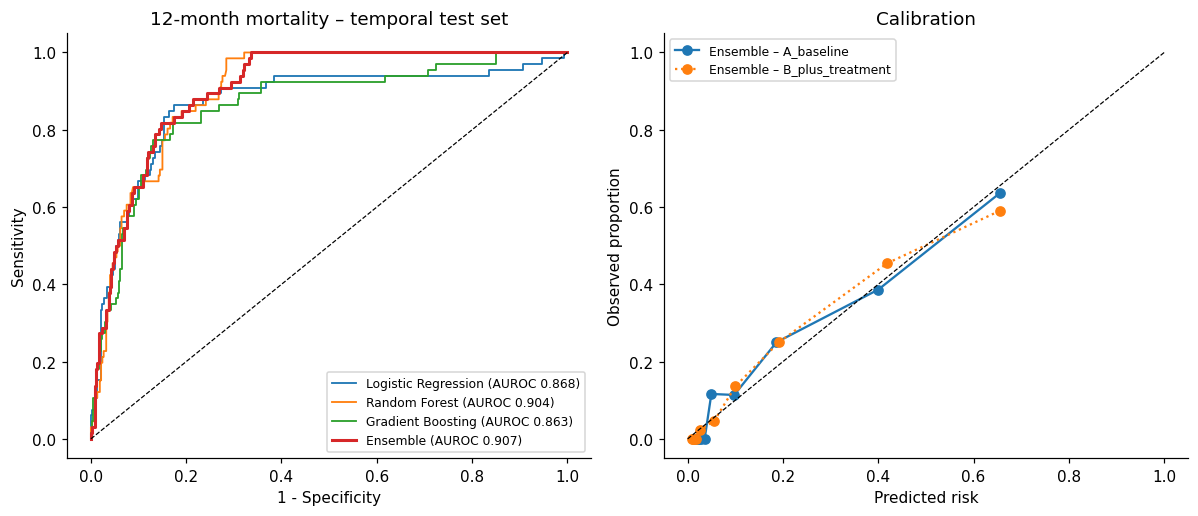

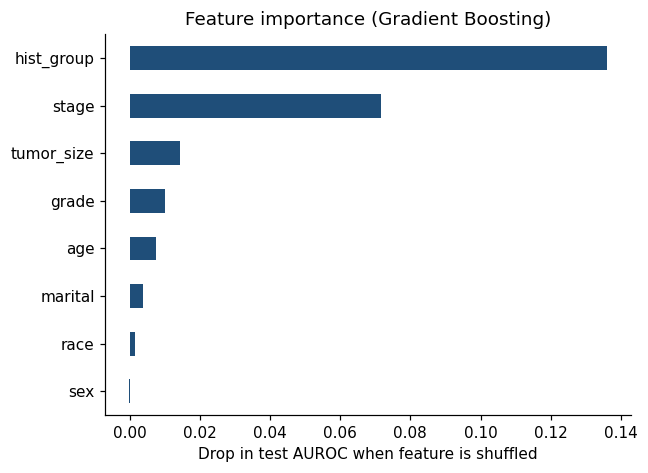

In [13]:
# ROC + calibration for the primary (baseline) feature set
fs = "A_baseline"; yte = test.y.values
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for name, p in test_preds[fs].items():
    fpr, tpr, _ = roc_curve(yte, p)
    axs[0].plot(fpr, tpr, lw=2 if name == "Ensemble" else 1.2, label=f"{name} (AUROC {roc_auc_score(yte, p):.3f})")
axs[0].plot([0, 1], [0, 1], "k--", lw=0.8); axs[0].set_xlabel("1 - Specificity"); axs[0].set_ylabel("Sensitivity")
axs[0].set_title(f"{HORIZON}-month mortality – temporal test set"); axs[0].legend(loc="lower right", fontsize=8)
for fsn, ls in [("A_baseline", "-"), ("B_plus_treatment", ":")]:
    pt, pp = calibration_curve(yte, test_preds[fsn]["Ensemble"], n_bins=10, strategy="quantile")
    axs[1].plot(pp, pt, marker="o", ls=ls, label=f"Ensemble – {fsn}")
axs[1].plot([0, 1], [0, 1], "k--", lw=0.8); axs[1].set_xlabel("Predicted risk"); axs[1].set_ylabel("Observed proportion")
axs[1].set_title("Calibration"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_roc_calibration.png", dpi=300); plt.show()

# permutation importance (gradient boosting, baseline set)
feats = FEATURE_SETS[fs]; gb = fitted[fs]["Gradient Boosting"]
sub = test.sample(min(4000, len(test)), random_state=SEED)
pi = permutation_importance(gb, sub[feats], sub.y.values, n_repeats=5, scoring="roc_auc", random_state=SEED)
imp = pd.Series(pi.importances_mean, index=feats).sort_values()
imp.to_csv(f"{OUT}/permutation_importance.csv")
fig, ax = plt.subplots(figsize=(6, 0.4 * len(imp) + 1.2)); imp.plot.barh(ax=ax, color="#1f4e79")
ax.set_xlabel("Drop in test AUROC when feature is shuffled"); ax.set_title("Feature importance (Gradient Boosting)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_feature_importance.png", dpi=300); plt.show()

## 7b. Clinical-use analyses (all fixed in advance; state each in Methods)

**Clinical question:** in a *diagnosed* young patient, does a multivariable model estimate 12-month mortality better than stage alone, and is the estimate usable for counselling and treatment-intensity planning? Not screening, not early detection.

**7b-1 Stage-only benchmark, recalibration, paired AUROC differences.** Recalibration is fitted on the training out-of-fold predictions only and then applied to the test set.

In [14]:
from scipy.optimize import minimize_scalar
yte, ytr = test.y.values, train.y.values
FS, FS_LOC = "A_baseline", "A_plus_location"

def lg(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def fit_recal(p, y): return LogisticRegression(C=1e10, max_iter=1000).fit(lg(p).reshape(-1, 1), y)
def apply_recal(mod, p): return mod.predict_proba(lg(p).reshape(-1, 1))[:, 1]
def cal_si(y, p):
    z = lg(p); slope = LogisticRegression(C=1e10, max_iter=1000).fit(z.reshape(-1, 1), y).coef_[0, 0]
    f = lambda a: -np.sum(y * (a + z) - np.log1p(np.exp(a + z)))
    return slope, minimize_scalar(f).x            # intercept = calibration-in-the-large (slope fixed at 1)
def paired_delta(y, p1, p2, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); v = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() == y[b].max(): continue
        v.append(roc_auc_score(y[b], p1[b]) - roc_auc_score(y[b], p2[b]))
    return roc_auc_score(y, p1) - roc_auc_score(y, p2), *np.percentile(v, [2.5, 97.5])
def slope_ci(y, p, n=N_BOOT):
    rng = np.random.default_rng(SEED); v = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() == y[b].max(): continue
        v.append(cal_si(y[b], p[b])[0])
    return np.percentile(v, [2.5, 97.5])

so = make_models(["stage"])["Logistic Regression"]
oof_so = cross_val_predict(so, train[["stage"]], ytr, cv=skf, method="predict_proba")[:, 1]
so.fit(train[["stage"]], ytr); p_so = so.predict_proba(test[["stage"]])[:, 1]

sh = make_models(["stage", "hist_group"])["Logistic Regression"]
oof_sh = cross_val_predict(sh, train[["stage", "hist_group"]], ytr, cv=skf, method="predict_proba")[:, 1]
sh.fit(train[["stage", "hist_group"]], ytr); p_sh = sh.predict_proba(test[["stage", "hist_group"]])[:, 1]

cands = {
 "Stage-only LR":               (p_so, oof_so),
 "Stage + histology LR":        (p_sh, oof_sh),
 "Logistic regression (set A)": (test_preds[FS]["Logistic Regression"], oof_store[FS]["Logistic Regression"]),
 "Ensemble (set A)":            (test_preds[FS]["Ensemble"], oof_store[FS]["Ensemble"]),
 "Ensemble (set A + location)": (test_preds[FS_LOC]["Ensemble"], oof_store[FS_LOC]["Ensemble"]),
}
p_raw, p_rc, recal_mods, oof_rc, rows = {}, {}, {}, {}, []
for nm, (pt_, po_) in cands.items():
    rm = fit_recal(po_, ytr); recal_mods[nm] = rm
    p_raw[nm] = pt_; p_rc[nm] = apply_recal(rm, pt_); oof_rc[nm] = apply_recal(rm, po_)
    s0, a0 = cal_si(yte, pt_); s1, a1 = cal_si(yte, p_rc[nm]); lo, hi = boot_ci(yte, pt_, roc_auc_score); sl, sh_ci = slope_ci(yte, p_rc[nm])
    rows.append(dict(Model=nm, AUROC=roc_auc_score(yte, pt_), AUROC_CI=f"{lo:.3f}-{hi:.3f}",
        Brier_raw=brier_score_loss(yte, pt_), Brier_recal=brier_score_loss(yte, p_rc[nm]),
        Slope_raw=s0, Intercept_raw=a0, Slope_recal=s1, Slope_recal_CI=f"{sl:.2f}-{sh_ci:.2f}", Intercept_recal=a1))
tab_cal = pd.DataFrame(rows); tab_cal.to_csv(f"{OUT}/recalibration_table.csv", index=False); display(tab_cal.round(3))

rows = []
for nm in [k for k in cands if k not in ("Stage-only LR", "Stage + histology LR")]:
    e, lo, hi = paired_delta(yte, p_raw[nm], p_so)
    rows.append(dict(Comparison=f"{nm} minus stage-only", Delta_AUROC=e, CI=f"{lo:+.3f} to {hi:+.3f}"))
e, lo, hi = paired_delta(yte, p_raw["Ensemble (set A)"], p_raw["Stage + histology LR"])
rows.append(dict(Comparison="Ensemble (set A) minus stage + histology LR", Delta_AUROC=e, CI=f"{lo:+.3f} to {hi:+.3f}"))
e, lo, hi = paired_delta(yte, p_raw["Stage + histology LR"], p_raw["Stage-only LR"])
rows.append(dict(Comparison="Stage + histology LR minus stage-only", Delta_AUROC=e, CI=f"{lo:+.3f} to {hi:+.3f}"))
e, lo, hi = paired_delta(yte, p_raw["Ensemble (set A + location)"], p_raw["Ensemble (set A)"])
rows.append(dict(Comparison="Ensemble (A + location) minus Ensemble (A)", Delta_AUROC=e, CI=f"{lo:+.3f} to {hi:+.3f}"))
tab_delta = pd.DataFrame(rows); tab_delta.to_csv(f"{OUT}/auroc_differences.csv", index=False); display(tab_delta.round(3))
print(f"Test n = {len(yte)}, events = {int(yte.sum())} ({yte.mean():.1%}). With this few events, a CI that includes 0 means 'no demonstrable gain', not 'equivalent'.")

,Model,AUROC,AUROC_CI,Brier_raw,Brier_recal,Slope_raw,Intercept_raw,Slope_recal,Slope_recal_CI,Intercept_recal
0,Stage-only LR,0.834,0.788-0.877,0.098,0.098,1.075,-0.229,1.037,0.83-1.32,-0.222
1,Stage + histology LR,0.865,0.814-0.909,0.088,0.088,0.809,0.052,0.774,0.63-0.97,0.069
2,Logistic regression (set A),0.868,0.812-0.920,0.087,0.086,0.784,0.069,0.819,0.66-1.04,0.064
3,Ensemble (set A),0.907,0.876-0.935,0.085,0.086,1.081,-0.014,0.890,0.74-1.08,0.055
4,Ensemble (set A + location),0.906,0.876-0.934,0.087,0.088,1.039,-0.003,0.854,0.71-1.04,0.057


,Comparison,Delta_AUROC,CI
0,Logistic regression (set A) minus stage-only,0.034,-0.013 to +0.086
1,Ensemble (set A) minus stage-only,0.073,+0.041 to +0.109
2,Ensemble (set A + location) minus stage-only,0.073,+0.038 to +0.110
3,Ensemble (set A) minus stage + histology LR,0.042,+0.018 to +0.070
4,Stage + histology LR minus stage-only,0.031,-0.007 to +0.073
5,Ensemble (A + location) minus Ensemble (A),-0.001,-0.006 to +0.004


Test n = 439, events = 66 (15.0%). With this few events, a CI that includes 0 means 'no demonstrable gain', not 'equivalent'.


**7b-2 Decision curve analysis.** Net benefit of using each model to select patients for a higher-intensity pathway, across threshold probabilities. If the model line is not above the stage-only line, ML adds no clinical net benefit.

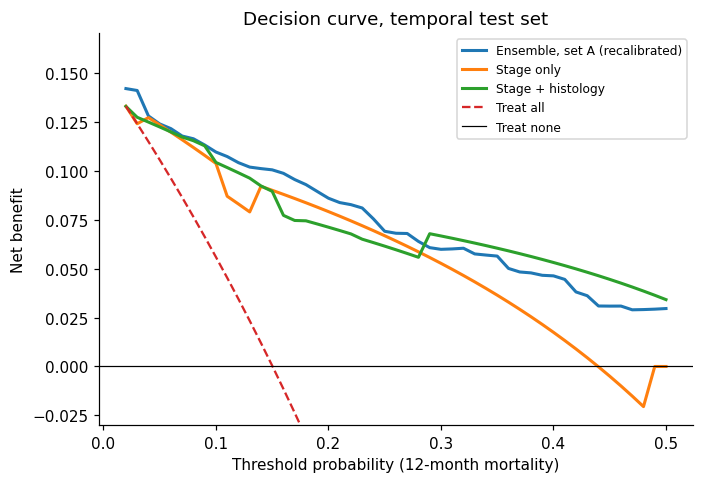

,Threshold,NB_ensemble,NB_stage_only,NB_treat_all,Diff,Diff_CI
0,0.05,0.1240,0.1235,0.1056,0.0005,-0.0122 to +0.0137
1,0.10,0.1096,0.1038,0.0559,0.0058,-0.0094 to +0.0187
2,0.15,0.1005,0.0900,0.0004,0.0105,-0.0039 to +0.0243
3,0.20,0.0860,0.0792,-0.0621,0.0068,-0.0114 to +0.0228
4,0.30,0.0599,0.0527,-0.2138,0.0072,-0.0135 to +0.0283


In [15]:
def net_benefit(p, y, pts):
    n = len(y); out = []
    for t in pts:
        pred = p >= t; tp = (pred & (y == 1)).sum(); fp = (pred & (y == 0)).sum()
        out.append(tp / n - fp / n * t / (1 - t))
    return np.array(out)
pts = np.arange(0.02, 0.51, 0.01); prev = yte.mean()
nb_all = prev - (1 - prev) * pts / (1 - pts)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(pts, net_benefit(p_rc["Ensemble (set A)"], yte, pts), lw=2, label="Ensemble, set A (recalibrated)")
ax.plot(pts, net_benefit(p_rc["Stage-only LR"], yte, pts), lw=2, label="Stage only")
ax.plot(pts, net_benefit(p_rc["Stage + histology LR"], yte, pts), lw=2, label="Stage + histology")
ax.plot(pts, nb_all, "--", label="Treat all"); ax.axhline(0, color="k", lw=.8, label="Treat none")
ax.set_ylim(-0.03, prev + 0.02); ax.set_xlabel("Threshold probability (12-month mortality)"); ax.set_ylabel("Net benefit")
ax.set_title("Decision curve, temporal test set"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_decision_curve.png", dpi=300); plt.show()

rows = []; rng = np.random.default_rng(SEED)
for t in [0.05, 0.10, 0.15, 0.20, 0.30]:
    a = net_benefit(p_rc["Ensemble (set A)"], yte, [t])[0]; b_ = net_benefit(p_rc["Stage-only LR"], yte, [t])[0]; dd = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(yte), len(yte))
        dd.append(net_benefit(p_rc["Ensemble (set A)"][i], yte[i], [t])[0] - net_benefit(p_rc["Stage-only LR"][i], yte[i], [t])[0])
    rows.append(dict(Threshold=t, NB_ensemble=a, NB_stage_only=b_, NB_treat_all=prev - (1 - prev) * t / (1 - t),
                     Diff=a - b_, Diff_CI=f"{np.percentile(dd, 2.5):+.4f} to {np.percentile(dd, 97.5):+.4f}"))
tab_dca = pd.DataFrame(rows); tab_dca.to_csv(f"{OUT}/decision_curve_table.csv", index=False); display(tab_dca.round(4))

**7b-3 Risk tiers.** Cut-offs are fixed *before* looking at test results: the 50th and 80th percentiles of recalibrated risk in the training out-of-fold predictions. Tiers are then applied unchanged to the test set.

In [16]:
from statsmodels.stats.proportion import proportion_confint
MODEL_T = "Ensemble (set A)"
c1, c2 = np.quantile(oof_rc[MODEL_T], [0.5, 0.8])
def tier_of(p): return pd.Categorical(np.where(p < c1, "Low", np.where(p < c2, "Intermediate", "High")), ["Low", "Intermediate", "High"])
def tier_table(p, y, label):
    t = pd.DataFrame({"tier": tier_of(p), "y": y, "p": p}); g = t.groupby("tier", observed=False)
    out = g.agg(n=("y", "size"), deaths=("y", "sum"), mean_predicted=("p", "mean")).reset_index()
    out["observed_12m_mortality"] = out.deaths / out.n
    ci = [proportion_confint(r.deaths, r.n, method="wilson") if r.n else (np.nan, np.nan) for r in out.itertuples()]
    out["95%CI"] = [f"{a:.1%}-{b:.1%}" for a, b in ci]; out.insert(0, "set", label); return out
print(f"Cut-offs on recalibrated risk: low < {c1:.3f} <= intermediate < {c2:.3f} <= high")
tab_tier = pd.concat([tier_table(p_rc[MODEL_T], yte, "Test (temporal)"), tier_table(oof_rc[MODEL_T], ytr, "Train (out-of-fold)")])
tab_tier.to_csv(f"{OUT}/risk_tiers.csv", index=False); display(tab_tier.round(3))

Cut-offs on recalibrated risk: low < 0.093 <= intermediate < 0.565 <= high


,set,tier,n,deaths,mean_predicted,observed_12m_mortality,95%CI
0,Test (temporal),Low,299,8,0.022,0.027,1.4%-5.2%
1,Test (temporal),Intermediate,93,28,0.263,0.301,21.7%-40.1%
2,Test (temporal),High,47,30,0.705,0.638,49.5%-76.0%
0,Train (out-of-fold),Low,460,12,0.030,0.026,1.5%-4.5%
1,Train (out-of-fold),Intermediate,276,77,0.257,0.279,22.9%-33.5%
2,Train (out-of-fold),High,185,128,0.717,0.692,62.2%-75.4%


**7b-4 Histology-stratified performance.** Test-set strata are too small, so this uses pooled 5-fold cross-validated predictions across all years (exploratory). Strata with <10 events or <10 survivors are reported as not estimable.

In [17]:
mm = m.reset_index(drop=True); y_all = mm.y.values; feats_A = FEATURE_SETS[FS]
oof_a_stage = cross_val_predict(make_models(["stage"])["Logistic Regression"], mm[["stage"]], y_all, cv=skf, method="predict_proba")[:, 1]
oof_a_ens = np.mean([cross_val_predict(e, mm[feats_A], y_all, cv=skf, method="predict_proba")[:, 1] for e in make_models(feats_A).values()], axis=0)
rows = []
for g in ["All"] + [h for h in ["Adenocarcinoma", "Neuroendocrine", "Solid pseudopapillary", "Other"] if h in set(mm.hist_group)]:
    k = np.ones(len(mm), bool) if g == "All" else (mm.hist_group == g).values
    n, ev = k.sum(), int(y_all[k].sum()); st = mm.stage[k]
    row = dict(Histology=g, n=int(n), events=ev, mortality_12m=ev / n, pct_distant=(st == "Distant").mean(),
               AUROC_stage=np.nan, AUROC_full=np.nan, Delta_CI="not estimable")
    if ev >= 10 and (n - ev) >= 10:
        e, lo, hi = paired_delta(y_all[k], oof_a_ens[k], oof_a_stage[k])
        row.update(AUROC_stage=roc_auc_score(y_all[k], oof_a_stage[k]), AUROC_full=roc_auc_score(y_all[k], oof_a_ens[k]), Delta_CI=f"{e:+.3f} ({lo:+.3f} to {hi:+.3f})")
    rows.append(row)
tab_hist = pd.DataFrame(rows); tab_hist.to_csv(f"{OUT}/histology_stratified.csv", index=False); display(tab_hist.round(3))
print("12-month mortality by histology x stage (n, % dead):")
x = mm.groupby(["hist_group", "stage"]).y.agg(["size", "mean"]).round(3); display(x)

,Histology,n,events,mortality_12m,pct_distant,AUROC_stage,AUROC_full,Delta_CI
0,All,1360,283,0.208,0.351,0.809,0.899,+0.090 (+0.069 to +0.109)
1,Adenocarcinoma,350,186,0.531,0.654,0.701,0.737,+0.035 (-0.008 to +0.081)
2,Neuroendocrine,570,38,0.067,0.305,0.752,0.813,+0.061 (+0.025 to +0.102)
3,Solid pseudopapillary,277,5,0.018,0.029,NaN,NaN,not estimable
4,Other,163,54,0.331,0.411,0.766,0.821,+0.055 (+0.002 to +0.106)


12-month mortality by histology x stage (n, % dead):


size   mean
hist_group            stage                 
Adenocarcinoma        Distant     229  0.686
                      Localized    27  0.222
                      Regional     87  0.241
                      Unknown       7  0.286
Neuroendocrine        Distant     174  0.161
                      Localized   284  0.011
                      Regional     97  0.072
                      Unknown      15  0.000
Other                 Distant      67  0.642
                      Localized    40  0.125
                      Regional     29  0.069
                      Unknown      27  0.148
Solid pseudopapillary Distant       8  0.000
                      Localized   205  0.000
                      Regional     54  0.000
                      Unknown      10  0.500

**7b-5 Second temporal split.** Repeats the whole comparison (CV on train, test on later years, recalibration on train) for several split years to show whether the conclusion depends on the split.

In [18]:
def run_split(split_year, feats=None, data=None):
    data = m if data is None else data; feats = feats or FEATURE_SETS[FS]
    tr, te = data[data.year < split_year], data[data.year >= split_year]; ytr_, yte_ = tr.y.values, te.y.values
    P, O = [], []
    for e in make_models(feats).values():
        O.append(cross_val_predict(e, tr[feats], ytr_, cv=skf, method="predict_proba")[:, 1]); e.fit(tr[feats], ytr_); P.append(e.predict_proba(te[feats])[:, 1])
    ens, oof = np.mean(P, 0), np.mean(O, 0)
    s = make_models(["stage"])["Logistic Regression"]; s.fit(tr[["stage"]], ytr_); pso = s.predict_proba(te[["stage"]])[:, 1]
    sh_ = make_models(["stage", "hist_group"])["Logistic Regression"]; sh_.fit(tr[["stage", "hist_group"]], ytr_); psh = sh_.predict_proba(te[["stage", "hist_group"]])[:, 1]
    e2, lo2, hi2 = paired_delta(yte_, ens, psh)
    e_, lo, hi = paired_delta(yte_, ens, pso)
    prc = apply_recal(fit_recal(oof, ytr_), ens); s0, a0 = cal_si(yte_, ens); s1, a1 = cal_si(yte_, prc)
    return dict(Split=f"train<{split_year} / test>={split_year}", n_train=len(tr), n_test=len(te), test_events=int(yte_.sum()),
        test_mortality=yte_.mean(), train_mortality=ytr_.mean(), CV_AUROC_train=roc_auc_score(ytr_, oof), AUROC_ensemble=roc_auc_score(yte_, ens),
        AUROC_stage_only=roc_auc_score(yte_, pso), AUROC_stage_hist=roc_auc_score(yte_, psh), Delta_vs_stage_hist=f"{e2:+.3f} ({lo2:+.3f} to {hi2:+.3f})", Delta=e_, Delta_CI=f"{lo:+.3f} to {hi:+.3f}", Slope_raw=s0, Slope_recal=s1)
tab_splits = pd.DataFrame([run_split(y_) for y_ in sorted({2014, SPLIT2, TEST_FROM})])
tab_splits.to_csv(f"{OUT}/temporal_split_robustness.csv", index=False); display(tab_splits.round(3))
print("Test vs CV AUROC differs by model (higher for ensemble/RF, lower for LR/GB); compare stage mix and mortality between periods:")
m["period"] = np.where(m.year < TEST_FROM, f"<{TEST_FROM}", f">={TEST_FROM}")
display(pd.crosstab(m.period, m.stage, normalize="index").round(3)); print(m.groupby("period").y.mean().round(3).to_string())

,Split,n_train,n_test,test_events,test_mortality,train_mortality,CV_AUROC_train,AUROC_ensemble,AUROC_stage_only,AUROC_stage_hist,Delta_vs_stage_hist,Delta,Delta_CI,Slope_raw,Slope_recal
0,train<2014 / test>=2014,535,825,121,0.147,0.303,0.865,0.910,0.840,0.893,+0.017 (+0.007 to +0.027),0.070,+0.043 to +0.095,1.225,1.00
1,train<2016 / test>=2016,724,636,93,0.146,0.262,0.891,0.904,0.833,0.885,+0.019 (+0.009 to +0.030),0.071,+0.038 to +0.103,1.088,0.87
2,train<2018 / test>=2018,921,439,66,0.150,0.236,0.894,0.907,0.834,0.865,+0.042 (+0.018 to +0.070),0.073,+0.041 to +0.109,1.081,0.89


Test vs CV AUROC differs by model (higher for ensemble/RF, lower for LR/GB); compare stage mix and mortality between periods:


stage,Distant,Localized,Regional,Unknown
period,,,,
<2018,0.393,0.355,0.208,0.043
>=2018,0.264,0.522,0.171,0.043


period
<2018     0.236
>=2018    0.150


## 7c. Dr. Bhut point 4: proportional hazards. Restricted mean survival time and a time-varying stage effect

In [19]:
from lifelines.utils import restricted_mean_survival_time as rmst
sg = d[d.stage.isin(["Localized", "Regional", "Distant"])].copy(); sg["stage"] = sg.stage.astype(str)
def rmst_by_stage(data, tau):
    out = {}
    for s_, g in data.groupby("stage"):
        out[s_] = rmst(KaplanMeierFitter().fit(g.time, g.event), t=tau)
    return pd.Series(out)
rows = []
for tau in (12, 36, 60):
    est = rmst_by_stage(sg, tau); bt = pd.DataFrame([rmst_by_stage(sg.sample(len(sg), replace=True, random_state=i), tau) for i in range(300)])
    for s_ in est.index:
        rows.append(dict(tau_months=tau, Stage=s_, RMST_months=est[s_], CI=f"{bt[s_].quantile(.025):.1f}-{bt[s_].quantile(.975):.1f}"))
    for a_, b_ in [("Distant", "Localized"), ("Regional", "Localized")]:
        df_ = bt[a_] - bt[b_]; rows.append(dict(tau_months=tau, Stage=f"{a_} minus {b_}", RMST_months=est[a_] - est[b_], CI=f"{df_.quantile(.025):.1f} to {df_.quantile(.975):.1f}"))
tab_rmst = pd.DataFrame(rows); tab_rmst.to_csv(f"{OUT}/rmst_by_stage.csv", index=False); display(tab_rmst.round(1))

# piecewise Cox: same covariates as the main model, stage effect estimated separately in 0-12 and >12 months
p1 = cox_df.copy(); p1["event"] = ((p1.event == 1) & (p1.time <= 12)).astype(float); p1["time"] = p1.time.clip(upper=12)
p2 = cox_df[cox_df.time > 12].copy(); p2["entry"] = 12.0
rows = []
for nm, pdx, kw in [("0-12 months", p1, {}), (">12 months", p2, {"entry_col": "entry"})]:
    pdx = pdx.loc[:, (pdx.std() > 0) | pdx.columns.isin(["time", "event", "entry"])]
    try: c_ = CoxPHFitter().fit(pdx, "time", "event", **kw)
    except Exception as ex:
        print(nm, "unpenalised fit failed (", str(ex)[:60], ") -> penalizer 0.01"); c_ = CoxPHFitter(penalizer=0.01).fit(pdx, "time", "event", **kw)
    for v in [c for c in c_.summary.index if c.startswith("stage_")]:
        r_ = c_.summary.loc[v]; rows.append(dict(Window=nm, Term=v, HR=r_["exp(coef)"], CI=f"{r_['exp(coef) lower 95%']:.2f}-{r_['exp(coef) upper 95%']:.2f}", events=int(pdx.event.sum())))
tab_tv = pd.DataFrame(rows); tab_tv.to_csv(f"{OUT}/time_varying_stage_hr.csv", index=False); display(tab_tv.round(2))

,tau_months,Stage,RMST_months,CI
0,12,Distant,8.3,7.9-8.7
1,12,Localized,11.9,11.8-11.9
2,12,Regional,11.5,11.2-11.7
3,12,Distant minus Localized,-3.5,-4.0 to -3.2
4,12,Regional minus Localized,-0.4,-0.6 to -0.2
5,36,Distant,17.2,15.9-18.4
6,36,Localized,35.1,34.6-35.5
7,36,Regional,29.9,28.7-31.1
8,36,Distant minus Localized,-17.9,-19.0 to -16.5
9,36,Regional minus Localized,-5.2,-6.5 to -3.9


,Window,Term,HR,CI,events
0,0-12 months,stage_Regional,1.91,0.99-3.67,296
1,0-12 months,stage_Distant,7.44,4.14-13.39,296
2,0-12 months,stage_Unknown,2.00,0.86-4.63,296
3,>12 months,stage_Regional,3.11,1.97-4.90,266
4,>12 months,stage_Distant,7.36,4.85-11.16,266
5,>12 months,stage_Unknown,2.22,1.12-4.37,266


## 7d. Dr. Bhut point 5: missing data. Missingness table and sensitivity analyses

In [20]:
flag = pd.DataFrame({"Stage": d.stage.astype(str) == "Unknown", "Grade": d.grade == "Unknown", "Race": d.race == "Unknown",
    "Marital status": d.marital == "Unknown", "Tumor size": d.tumor_size.isna(), "Surgery": d.surgery == "Unknown", "Radiation": d.radiation == "Unknown"})
strata = {"Overall": pd.Series("All", index=d.index), "Period": pd.cut(d.year, [2003, 2009, 2017, 2021], labels=["2004-09", "2010-17", "2018-21"]),
          "Stage": d.stage.astype(str), "Histology": d.hist_group}
cols = {}
for sname, sv in strata.items():
    for lv in sv.dropna().unique(): cols[f"{sname}: {lv}"] = flag[sv == lv].mean()
tab_miss = pd.DataFrame(cols).T.mul(100).round(1)
tab_miss.insert(0, "n", [int((strata[k.split(': ')[0]] == (k.split(': ')[1] if k.split(': ')[0] != 'Overall' else 'All')).sum()) if k.split(': ')[0] != 'Period' else int((strata['Period'].astype(str) == k.split(': ')[1]).sum()) for k in tab_miss.index])
tab_miss.to_csv(f"{OUT}/missingness_table.csv"); print("% missing / unknown"); display(tab_miss)

# ---- sensitivity analyses on the temporal test set (Delta AUROC = full model - stage only) ----
def quick_eval(data, feats, split=TEST_FROM):
    tr, te = data[data.year < split], data[data.year >= split]; P = []
    for e in make_models(feats).values():
        e.fit(tr[feats], tr.y.values); P.append(e.predict_proba(te[feats])[:, 1])
    s = make_models(["stage"])["Logistic Regression"].fit(tr[["stage"]], tr.y.values)
    return te.y.values, np.mean(P, 0), s.predict_proba(te[["stage"]])[:, 1]
sens = []
def add_sens(label, y_, pf, ps, note=""):
    e, lo, hi = paired_delta(y_, pf, ps); sens.append(dict(Analysis=label, n_test=len(y_), AUROC_full=roc_auc_score(y_, pf), AUROC_stage=roc_auc_score(y_, ps), Delta=e, CI=f"{lo:+.3f} to {hi:+.3f}", note=note))
add_sens("Primary (set A)", *quick_eval(m, feats_A))
add_sens("Without grade", *quick_eval(m, [f for f in feats_A if f != "grade"]))
add_sens("Known stage only", *quick_eval(m[m.stage != "Unknown"], feats_A))
add_sens("Known stage and grade", *quick_eval(m[(m.stage != "Unknown") & (m.grade != "Unknown")], feats_A))

# ---- multiple imputation (chained equations, 5 datasets): stage, grade, tumor size ----
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
M_IMP = 5; ST = {"Localized": 1, "Regional": 2, "Distant": 3}; GR = {"G1": 1, "G2": 2, "G3-4": 3}
Z = pd.DataFrame({"age": d.age, "male": (d.sex == "Male").astype(float), "year": d.year, "stage_ord": d.stage.astype(str).map(ST),
                  "grade_ord": d.grade.map(GR), "size": d.tumor_size, "chemo": (d.chemo == "Yes").astype(float), "rad": (d.radiation == "Yes").astype(float),
                  "event": d.event.astype(float), "log_time": np.log(d.time + 0.5)}, index=d.index)
Z = pd.concat([Z, pd.get_dummies(d.hist_group, prefix="h", dtype=float), pd.get_dummies(d.location, prefix="l", dtype=float), pd.get_dummies(d.race, prefix="r", dtype=float)], axis=1)
inv_st = {v: k for k, v in ST.items()}; inv_gr = {v: k for k, v in GR.items()}
def cox_small(dd):
    s_ = dd.stage.astype(str); g_ = dd.grade.astype(str)
    X = pd.DataFrame({"age_per10yr": dd.age / 10, "male": (dd.sex == "Male").astype(float), "dx_year_per5": (dd.year - YEAR_MIN) / 5,
        "stage_Regional": (s_ == "Regional").astype(float), "stage_Distant": (s_ == "Distant").astype(float),
        "grade_G2": (g_ == "G2").astype(float), "grade_G3-4": (g_ == "G3-4").astype(float),
        "hist_NE": (dd.hist_group == "Neuroendocrine").astype(float), "hist_SPN": (dd.hist_group == "Solid pseudopapillary").astype(float), "hist_Other": (dd.hist_group == "Other").astype(float)}, index=dd.index)
    X["time"] = dd.time.clip(lower=0.5); X["event"] = dd.event; return X.loc[:, (X.std() > 0) | X.columns.isin(["time", "event"])]
coefs, ses, ml_rows = [], [], []
for i in range(M_IMP):
    imp_ = IterativeImputer(estimator=BayesianRidge(), sample_posterior=True, max_iter=10, random_state=SEED + i)
    Zi = pd.DataFrame(imp_.fit_transform(Z), columns=Z.columns, index=Z.index)
    di = d.copy(); di["stage"] = Zi.stage_ord.round().clip(1, 3).astype(int).map(inv_st); di["grade"] = Zi.grade_ord.round().clip(1, 3).astype(int).map(inv_gr); di["tumor_size"] = Zi["size"].clip(lower=1)
    cf = CoxPHFitter().fit(cox_small(di), "time", "event"); coefs.append(cf.params_["stage_Distant"]); ses.append(cf.standard_errors_["stage_Distant"])
    mi = di.loc[m.index].copy(); mi["y"] = m.y; ml_rows.append(quick_eval(mi, feats_A))
Qbar = np.mean(coefs); Ubar = np.mean(np.square(ses)); B = np.var(coefs, ddof=1); T = Ubar + (1 + 1 / M_IMP) * B
mi_hr = (np.exp(Qbar), np.exp(Qbar - 1.96 * np.sqrt(T)), np.exp(Qbar + 1.96 * np.sqrt(T)))
deltas = [roc_auc_score(y_, pf) - roc_auc_score(y_, ps) for y_, pf, ps in ml_rows]
y_, pf, ps = ml_rows[0]; _, lo0, hi0 = paired_delta(y_, pf, ps)
sens.append(dict(Analysis=f"Multiple imputation ({M_IMP} datasets), mean over imputations", n_test=len(y_), AUROC_full=np.mean([roc_auc_score(a, b) for a, b, c in ml_rows]),
    AUROC_stage=np.mean([roc_auc_score(a, c) for a, b, c in ml_rows]), Delta=np.mean(deltas), CI=f"range of Delta across imputations {min(deltas):+.3f} to {max(deltas):+.3f}", note="imputed: stage, grade, tumor size"))
tab_sens = pd.DataFrame(sens); tab_sens.to_csv(f"{OUT}/sensitivity_analyses.csv", index=False); display(tab_sens.round(3))
cc = CoxPHFitter().fit(cox_small(d[(d.stage.astype(str) != "Unknown") & (d.grade != "Unknown")]), "time", "event")
print(f"Distant vs localized HR: complete-case (known stage and grade) {np.exp(cc.params_['stage_Distant']):.2f} | multiple imputation {mi_hr[0]:.2f} (95% CI {mi_hr[1]:.2f}-{mi_hr[2]:.2f})")

% missing / unknown


,n,Stage,Grade,Race,Marital status,Tumor size,Surgery,Radiation
Overall: All,1406,4.6,52.9,0.0,4.2,15.2,0.8,0.4
Period: 2004-09,309,5.5,58.6,0.0,1.9,26.2,1.0,1.3
Period: 2010-17,637,3.9,47.1,0.0,3.9,14.0,1.1,0.3
Period: 2018-21,460,4.8,57.2,0.0,6.1,9.6,0.2,0.0
Stage: Distant,491,0.0,65.8,0.0,3.1,24.4,0.6,0.4
Stage: Localized,577,0.0,42.3,0.0,3.6,3.3,0.2,0.2
Stage: Unknown,64,100.0,89.1,0.0,21.9,87.5,9.4,1.6
Stage: Regional,274,0.0,43.8,0.0,3.3,6.9,0.4,0.7
Histology: Neuroendocrine,583,2.6,24.9,0.0,4.1,8.4,0.2,0.0
Histology: Other,168,17.3,69.6,0.0,1.8,35.1,3.6,1.2


,Analysis,n_test,AUROC_full,AUROC_stage,Delta,CI,note
0,Primary (set A),439,0.907,0.834,0.073,+0.041 to +0.109,
1,Without grade,439,0.901,0.834,0.067,+0.036 to +0.103,
2,Known stage only,420,0.926,0.857,0.070,+0.034 to +0.108,
3,Known stage and grade,189,0.934,0.843,0.091,+0.023 to +0.179,
4,"Multiple imputation (5 datasets), mean over im...",439,0.897,0.823,0.073,range of Delta across imputations +0.055 to +0...,"imputed: stage, grade, tumor size"


Distant vs localized HR: complete-case (known stage and grade) 8.16 | multiple imputation 6.91 (95% CI 4.97-9.63)


## 7d-2. Remaining reviewer points: pancreatoblastoma, histology effects over follow-up, and Cox missing-data sensitivity
Outputs: `other_histology_codes.csv`, `cox_pancreatoblastoma_sensitivity.csv`, `histology_piecewise_hr.csv`, `cox_stratified_by_histology.csv`, `cox_multiple_imputation.csv`, `cox_without_grade.csv`.


In [21]:
# ---- (a) What is inside "Other" histology, and a pancreatoblastoma (ICD-O-3 8971) sensitivity analysis ----
hcode = clean(raw[colmap["hist"][0]]).str.extract(r"(\d{4})")[0].reindex(d.index)
oth = hcode[d.hist_group == "Other"].value_counts().rename("n").to_frame()
oth["% of Other"] = (oth.n / oth.n.sum() * 100).round(1); oth.to_csv(f"{OUT}/other_histology_codes.csv"); display(oth.head(15))
n_pb = int((hcode == "8971").sum()); print(f"Pancreatoblastoma (8971) in cohort: n = {n_pb}")
cdf = cox_df.copy()
if n_pb >= 5:
    pb = (hcode == "8971").astype(float).reindex(cdf.index)
    cdf["hist_group_Pancreatoblastoma"] = pb
    if "hist_group_Other" in cdf: cdf["hist_group_Other"] = cdf["hist_group_Other"] * (1 - pb)
    cdf = cdf.loc[:, cdf.std() > 0]
    cpb = CoxPHFitter(penalizer=0.0).fit(cdf, "time", "event")
    r_ = cpb.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]; r_.columns = ["HR", "CI_low", "CI_high", "p"]
    r_.to_csv(f"{OUT}/cox_pancreatoblastoma_sensitivity.csv"); display(r_.filter(regex="stage|hist", axis=0).round(3))
else:
    print("Too few pancreatoblastoma cases to model separately; report the count and keep it in 'Other'.")

# ---- (b) Histology (and stage) effects by follow-up window, plus Cox stratified by histology ----
rows = []
for nm, pdx, kw in [("0-12 months", p1, {}), (">12 months", p2, {"entry_col": "entry"})]:
    pdx = pdx.loc[:, (pdx.std() > 0) | pdx.columns.isin(["time", "event", "entry"])]
    try: c_ = CoxPHFitter().fit(pdx, "time", "event", **kw)
    except Exception: c_ = CoxPHFitter(penalizer=0.01).fit(pdx, "time", "event", **kw)
    for v in [c for c in c_.summary.index if c.startswith(("stage_", "hist_group_"))]:
        r_ = c_.summary.loc[v]; rows.append(dict(Window=nm, Term=v, HR=r_["exp(coef)"], CI=f"{r_['exp(coef) lower 95%']:.2f}-{r_['exp(coef) upper 95%']:.2f}", events=int(pdx.event.sum())))
tab_hpw = pd.DataFrame(rows); tab_hpw.to_csv(f"{OUT}/histology_piecewise_hr.csv", index=False); display(tab_hpw.round(2))

sdf = cox_df.loc[:, [c for c in cox_df.columns if not c.startswith("hist_group_")]].copy(); sdf["hist_group"] = d.hist_group.astype(str)
cst = CoxPHFitter().fit(sdf, "time", "event", strata=["hist_group"])
r_ = cst.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]; r_.columns = ["HR", "CI_low", "CI_high", "p"]
r_.to_csv(f"{OUT}/cox_stratified_by_histology.csv"); print("Cox stratified by histology (no PH assumption for histology):"); display(r_.round(3))


,n,% of Other
0,,
8010,44,26.2
8000,39,23.2
8550,10,6.0
8470,9,5.4
9680,8,4.8
8971,7,4.2
8041,6,3.6
8013,5,3.0
8490,4,2.4


Pancreatoblastoma (8971) in cohort: n = 7


,HR,CI_low,CI_high,p
covariate,,,,
stage_Regional,2.545,1.756,3.688,0.000
stage_Distant,7.629,5.444,10.690,0.000
stage_Unknown,1.929,1.145,3.249,0.013
hist_group_Neuroendocrine,0.292,0.233,0.365,0.000
hist_group_Solid pseudopapillary,0.067,0.034,0.130,0.000
hist_group_Other,0.588,0.454,0.762,0.000
hist_group_Pancreatoblastoma,0.756,0.304,1.879,0.547


,Window,Term,HR,CI,events
0,0-12 months,stage_Regional,1.91,0.99-3.67,296
1,0-12 months,stage_Distant,7.44,4.14-13.39,296
2,0-12 months,stage_Unknown,2.00,0.86-4.63,296
3,0-12 months,hist_group_Neuroendocrine,0.23,0.16-0.33,296
4,0-12 months,hist_group_Solid pseudopapillary,0.12,0.05-0.31,296
5,0-12 months,hist_group_Other,0.78,0.57-1.08,296
6,>12 months,stage_Regional,3.11,1.97-4.90,266
7,>12 months,stage_Distant,7.36,4.85-11.16,266
8,>12 months,stage_Unknown,2.22,1.12-4.37,266
9,>12 months,hist_group_Neuroendocrine,0.34,0.25-0.46,266


Cox stratified by histology (no PH assumption for histology):


,HR,CI_low,CI_high,p
covariate,,,,
age_per10yr,1.247,1.039,1.496,0.018
male,1.153,0.973,1.366,0.100
dx_year_per5,0.954,0.874,1.041,0.287
stage_Regional,2.495,1.722,3.615,0.000
stage_Distant,7.256,5.184,10.156,0.000
stage_Unknown,2.045,1.215,3.441,0.007
grade_G2,1.503,1.015,2.227,0.042
grade_G3-4,3.229,2.178,4.788,0.000
grade_Unknown,2.736,1.943,3.853,0.000


In [22]:
# ---- (c) Full Cox model under multiple imputation (Rubin's rules) and without grade ----
def make_imputed(i):
    imp_ = IterativeImputer(estimator=BayesianRidge(), sample_posterior=True, max_iter=10, random_state=SEED + i)
    Zi = pd.DataFrame(imp_.fit_transform(Z), columns=Z.columns, index=Z.index)
    di = d.copy(); di["stage"] = Zi.stage_ord.round().clip(1, 3).astype(int).map(inv_st)
    di["grade"] = Zi.grade_ord.round().clip(1, 3).astype(int).map(inv_gr); di["tumor_size"] = Zi["size"].clip(lower=1); return di
fits = []
for i in range(M_IMP):
    X_ = cox_small(make_imputed(i)); fits.append(CoxPHFitter().fit(X_, "time", "event"))
terms = sorted(set.intersection(*[set(f.params_.index) for f in fits]))
rows = []
for tm in terms:
    q = np.array([f.params_[tm] for f in fits]); u = np.array([f.standard_errors_[tm] ** 2 for f in fits])
    Qb, Ub, Bv = q.mean(), u.mean(), q.var(ddof=1); Tt = Ub + (1 + 1 / M_IMP) * Bv
    rows.append(dict(Term=tm, HR=np.exp(Qb), CI_low=np.exp(Qb - 1.96 * np.sqrt(Tt)), CI_high=np.exp(Qb + 1.96 * np.sqrt(Tt))))
tab_mi_cox = pd.DataFrame(rows).set_index("Term"); tab_mi_cox.to_csv(f"{OUT}/cox_multiple_imputation.csv")
print("Cox model, pooled over multiple imputations (stage, grade, tumor size imputed):"); display(tab_mi_cox.round(3))

Xng = cox_small(d).drop(columns=[c for c in cox_small(d).columns if c.startswith("grade_")])
cng = CoxPHFitter().fit(Xng, "time", "event")
r_ = cng.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]; r_.columns = ["HR", "CI_low", "CI_high", "p"]
r_.to_csv(f"{OUT}/cox_without_grade.csv"); print("Cox model excluding grade:"); display(r_.round(3))


Cox model, pooled over multiple imputations (stage, grade, tumor size imputed):


,HR,CI_low,CI_high
Term,,,
age_per10yr,1.273,1.046,1.551
dx_year_per5,0.938,0.858,1.026
grade_G2,0.825,0.605,1.125
grade_G3-4,1.487,1.179,1.877
hist_NE,0.235,0.190,0.291
hist_Other,0.554,0.422,0.727
hist_SPN,0.065,0.033,0.126
male,1.180,0.990,1.406
stage_Distant,6.914,4.965,9.628


Cox model excluding grade:


,HR,CI_low,CI_high,p
covariate,,,,
age_per10yr,1.210,1.006,1.456,0.043
male,1.115,0.941,1.321,0.209
dx_year_per5,0.956,0.877,1.042,0.302
stage_Regional,2.245,1.642,3.069,0.000
stage_Distant,7.474,5.691,9.817,0.000
hist_NE,0.213,0.173,0.262,0.000
hist_SPN,0.063,0.032,0.121,0.000
hist_Other,0.652,0.510,0.834,0.001


## 7e. Summary of the new numbers (paste into Results; check against the tables)

In [23]:
print(f"Cohort: {len(d):,} patients; ML cohort {len(m):,}; test n={len(test)} events={int(test.y.sum())}")
print("\nCalibration (before -> after recalibration):"); display(tab_cal[["Model", "AUROC", "AUROC_CI", "Slope_raw", "Slope_recal", "Slope_recal_CI", "Intercept_raw", "Intercept_recal"]].round(2))
print("AUROC differences vs stage-only:"); display(tab_delta.round(3))
print("Risk tiers (test):"); display(tab_tier[tab_tier.set == "Test (temporal)"].round(3))
print("Robustness across temporal splits:"); display(tab_splits[["Split", "test_events", "AUROC_ensemble", "AUROC_stage_only", "AUROC_stage_hist", "Delta", "Delta_CI", "Delta_vs_stage_hist", "Slope_raw", "Slope_recal"]].round(3))

Cohort: 1,406 patients; ML cohort 1,360; test n=439 events=66

Calibration (before -> after recalibration):


,Model,AUROC,AUROC_CI,Slope_raw,Slope_recal,Slope_recal_CI,Intercept_raw,Intercept_recal
0,Stage-only LR,0.83,0.788-0.877,1.08,1.04,0.83-1.32,-0.23,-0.22
1,Stage + histology LR,0.87,0.814-0.909,0.81,0.77,0.63-0.97,0.05,0.07
2,Logistic regression (set A),0.87,0.812-0.920,0.78,0.82,0.66-1.04,0.07,0.06
3,Ensemble (set A),0.91,0.876-0.935,1.08,0.89,0.74-1.08,-0.01,0.06
4,Ensemble (set A + location),0.91,0.876-0.934,1.04,0.85,0.71-1.04,-0.00,0.06


AUROC differences vs stage-only:


,Comparison,Delta_AUROC,CI
0,Logistic regression (set A) minus stage-only,0.034,-0.013 to +0.086
1,Ensemble (set A) minus stage-only,0.073,+0.041 to +0.109
2,Ensemble (set A + location) minus stage-only,0.073,+0.038 to +0.110
3,Ensemble (set A) minus stage + histology LR,0.042,+0.018 to +0.070
4,Stage + histology LR minus stage-only,0.031,-0.007 to +0.073
5,Ensemble (A + location) minus Ensemble (A),-0.001,-0.006 to +0.004


Risk tiers (test):


,set,tier,n,deaths,mean_predicted,observed_12m_mortality,95%CI
0,Test (temporal),Low,299,8,0.022,0.027,1.4%-5.2%
1,Test (temporal),Intermediate,93,28,0.263,0.301,21.7%-40.1%
2,Test (temporal),High,47,30,0.705,0.638,49.5%-76.0%


Robustness across temporal splits:


,Split,test_events,AUROC_ensemble,AUROC_stage_only,AUROC_stage_hist,Delta,Delta_CI,Delta_vs_stage_hist,Slope_raw,Slope_recal
0,train<2014 / test>=2014,121,0.910,0.840,0.893,0.070,+0.043 to +0.095,+0.017 (+0.007 to +0.027),1.225,1.00
1,train<2016 / test>=2016,93,0.904,0.833,0.885,0.071,+0.038 to +0.103,+0.019 (+0.009 to +0.030),1.088,0.87
2,train<2018 / test>=2018,66,0.907,0.834,0.865,0.073,+0.041 to +0.109,+0.042 (+0.018 to +0.070),1.081,0.89


## 8. Auto-generated numbers for your manuscript

In [24]:
all_r = km_tab.set_index("Group")
best = res_ml[(res_ml.FeatureSet == "A_baseline") & (res_ml.Model == "Ensemble")].iloc[0]
lines = []
lines.append(f"COHORT: {len(raw):,} records -> {len(d):,} patients with pancreatic cancer diagnosed {YEAR_MIN}-{YEAR_MAX} (first/only primary, valid survival). Median age {d.age.median():.0f} y; {(d.sex=='Male').mean():.1%} male.")
lines.append(f"SURVIVAL: median OS {all_r.loc['All patients','Median OS (mo)']:.1f} months (95% CI {all_r.loc['All patients','Median 95% CI']}); 1-yr {all_r.loc['All patients','12-mo OS']}; 2-yr {all_r.loc['All patients','24-mo OS']}.")
for st in ["Localized", "Regional", "Distant"]:
    if st in all_r.index:
        lines.append(f"  {st}: n={all_r.loc[st,'N']:,}, median {all_r.loc[st,'Median OS (mo)']:.1f} mo ({all_r.loc[st,'Median 95% CI']}), 1-yr {all_r.loc[st,'12-mo OS']}")
if "stage_Distant" in res.index:
    r_ = res.loc["stage_Distant"]; lines.append(f"COX: distant vs localized HR {r_.HR:.2f} (95% CI {r_.CI_low:.2f}-{r_.CI_high:.2f}); model C-index {cph.concordance_index_:.3f}.")
lines.append(f"PREDICTION ({HORIZON}-mo mortality, baseline features, temporal validation train<{TEST_FROM}/test>={TEST_FROM}): train n={len(train):,}, test n={len(test):,}; "
             f"ensemble test AUROC {best.Test_AUROC:.3f} (95% CI {best.AUROC_CI}), AUPRC {best.Test_AUPRC:.3f}, Brier {best.Brier:.3f}.")
lines.append(f"AT {TARGET_SENS:.0%}-SENSITIVITY THRESHOLD (chosen on training OOF data): test sensitivity {best.Sensitivity:.3f}, specificity {best.Specificity:.3f}, PPV {best.PPV:.3f}, NPV {best.NPV:.3f}.")
lines.append(f"DATA SOURCE: {SEER_DB}. SOFTWARE: {SOFT_TXT}")
lines.append("LIMITATIONS TO STATE: SEER has no symptom, BMI, family-history or lab data; prognosis (not diagnostic triage) in patients already diagnosed; registry data, no external validation; treatment variables subject to immortal-time bias (set B exploratory); proportional-hazards assumption violated for some histology terms (time-averaged effects; stage re-estimated by period); grade unknown in about half of patients (sensitivity and imputation analyses).")
txt = "\n\n".join(lines); open(f"{OUT}/manuscript_numbers.txt", "w").write(txt); print(txt)

COHORT: 1,674 records -> 1,406 patients with pancreatic cancer diagnosed 2004-2021 (first/only primary, valid survival). Median age 32 y; 40.1% male.

SURVIVAL: median OS 155.0 months (95% CI 121.0-inf); 1-yr 78.5% (76.2%-80.6%); 2-yr 70.0% (67.4%-72.3%).

  Localized: n=577, median inf mo (inf-inf), 1-yr 97.5% (95.8%-98.5%)

  Regional: n=274, median 162.0 mo (107.0-inf), 1-yr 87.3% (82.7%-90.8%)

  Distant: n=491, median 13.0 mo (10.0-16.0), 1-yr 50.8% (46.2%-55.1%)

COX: distant vs localized HR 7.65 (95% CI 5.46-10.72); model C-index 0.867.

PREDICTION (12-mo mortality, baseline features, temporal validation train<2018/test>=2018): train n=921, test n=439; ensemble test AUROC 0.907 (95% CI 0.876-0.935), AUPRC 0.580, Brier 0.085.

AT 95%-SENSITIVITY THRESHOLD (chosen on training OOF data): test sensitivity 0.879, specificity 0.764, PPV 0.397, NPV 0.973.

DATA SOURCE: SEER*Stat Database: Incidence - SEER Research Data, 2000-2022. SOFTWARE: Analyses were performed in Python 3.13.18 (li

## 9. Download everything

In [25]:
zpath = "oncosense_results.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT)): z.write(os.path.join(OUT, f), f)
print("Saved:", sorted(os.listdir(OUT)))
try:
    from google.colab import files; files.download(zpath)
except ImportError:
    pass

Saved: ['age_groups.csv', 'auroc_differences.csv', 'cohort_flow.csv', 'cox_hazard_ratios.csv', 'cox_multiple_imputation.csv', 'cox_pancreatoblastoma_sensitivity.csv', 'cox_stratified_by_histology.csv', 'cox_without_grade.csv', 'decision_curve_table.csv', 'fig1_km_by_stage.png', 'fig2_cox_forest.png', 'fig3_roc_calibration.png', 'fig4_feature_importance.png', 'fig5_decision_curve.png', 'histology_piecewise_hr.csv', 'histology_stratified.csv', 'km_summary.csv', 'manuscript_numbers.txt', 'missingness_table.csv', 'ml_results.csv', 'other_histology_codes.csv', 'permutation_importance.csv', 'recalibration_table.csv', 'risk_tiers.csv', 'rmst_by_stage.csv', 'schoenfeld_tests.csv', 'sensitivity_analyses.csv', 'software_versions.txt', 'table1.csv', 'temporal_split_robustness.csv', 'time_varying_stage_hr.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>